# Maintain Velocity — Multi-Rodent Trail Render

Loads a maintain_velocity task transfer checkpoint, generates a rollout,
and renders a multi-rodent trail visualization with interactive camera controls
and high-res export.

In [13]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import functools
import io
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import numpy as np
import PIL.Image
from PIL import ImageDraw, ImageFont
from brax.training import distribution
from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks
import ipywidgets as widgets
from IPython.display import display as ipy_display

from scamper.environment.rodent import consts as rodent_consts
from scamper.environment.rodent import maintain_velocity

from scamper.agent.task_transfer.maintain_velocity.checkpoint_utils import (
    load_prior_checkpoint,
    load_task_transfer_metadata,
    load_task_transfer_brax_params,
    make_decoder_inference_fn,
    make_prior_inference_fn,
)
from scamper.agent.task_transfer.maintain_velocity.wrappers import (
    DecoderHighLevelWrapper,
    FlatObsWrapper,
    PriorDecoderHighLevelWrapper,
)
from scamper.agent.task_transfer.maintain_velocity.scratch_networks import (
    make_scratch_ppo_networks,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [27]:
# === Checkpoint & rollout configuration ===
CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260226_085923_279627"
CHECKPOINT_STEP = None  # None = latest step
NAME = "S3e-1"

EPISODE_LENGTH = 1000
SEED = 0

# Single-camera video rendering
RENDER_CAMERA = "close_profile-rodent"
RENDER_HEIGHT = 480
RENDER_WIDTH = 640
RENDER_FPS = 50

# === Trail configuration ===
TRAIL_NUM_FRAMES = 5  # rodent copies (ignored if override is set)
TRAIL_T_START = 0
TRAIL_T_END = 300
TRAIL_TIMESTEPS_OVERRIDE = (
    []
)  # explicit timesteps, e.g. [0, 111, 150, 222, 400, 600, 700]; empty = linspace

# Trajectory trace line
TRAIL_LINE_STEP = 5
TRAIL_LINE_RADIUS = 0.003
TRAIL_LINE_RGB = (189, 19, 0)
TRAIL_LINE_ALPHA = 0.8

# Initial camera (world coordinates)
TRAIL_CAM_POS = [-0.7, 0.1, 0.25]
TRAIL_CAM_LOOKAT = [0.0, 0.425, 0.0]
TRAIL_CAM_FOVY = 45

# High-res render resolution
TRAIL_RENDER_HEIGHT = 1080
TRAIL_RENDER_WIDTH = 2048

# Output directory
OUTPUT_DIR = Path(
    f"/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/maintain_velocity_trails/{NAME}"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load Checkpoint

In [28]:
# Load metadata to get config and determine mode
ckpt_info = load_task_transfer_metadata(CHECKPOINT_PATH, step=CHECKPOINT_STEP)
config = ckpt_info["config"]
training_metadata = ckpt_info["training_metadata"]
ckpt_step = ckpt_info["step"]

mode = config["mode"]
ckpt_cfg = config["checkpoint_config"]

print(f"Loaded checkpoint at step: {ckpt_step}")
print(f"Training mode: {mode}")
print(f"Training metadata: {training_metadata}")

Loaded checkpoint at step: 26
Training mode: decoder_only
Training metadata: {'completed_timesteps': 400000000, 'eval_step': 26, 'wandb_run_id': 'S0.3_decoder_only_seed0_260226_085923_279627', 'run_id': '260226_085923_279627', 'mode': 'decoder_only', 'training_complete': True}


In [29]:
# Load frozen networks from the prior checkpoint
prior_checkpoint_path = config["checkpoint"]["path"]
prior_checkpoint_step = config["checkpoint"]["step"]

print(f"Loading frozen networks from prior checkpoint: {prior_checkpoint_path}")

(
    encoder_params,
    prior_params,
    decoder_params,
    normalizer_params,
    _,
) = load_prior_checkpoint(prior_checkpoint_path, prior_checkpoint_step)

latent_size = ckpt_cfg["network_config"]["intention_size"]
proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]
action_size = ckpt_cfg["network_config"]["action_size"]

print(f"Latent size: {latent_size}")
print(f"Proprio size: {proprio_size}")
print(f"Action size: {action_size}")

Loading frozen networks from prior checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/prior_checkpoints/golden_rodent_prior_jax
Latent size: 16
Proprio size: 277
Action size: 38


## Create Environment

In [30]:
# Create environment config from checkpoint
env_cfg = maintain_velocity.default_config()

# Set XML variant
xml_variant = config["env"].get("xml_variant", "full-collisions")
if xml_variant == "limited-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_XML_PATH
elif xml_variant == "full-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_FULL_COLLISION_XML
elif xml_variant == "no-tail-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_NO_TAIL_COLLISION_XML
else:
    raise ValueError(f"Unknown xml_variant: {xml_variant}")

env_cfg.mujoco_impl = config["env"].get("mujoco_impl", "jax")
env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
env_cfg.init_z = config["env"]["init_z"]
env_cfg.target_speed = config["env"]["target_speed"]

# Set actuator type from checkpoint config (matches train.py logic)
if mode == "scratch":
    env_cfg.torque_actuators = config.get("scratch", {}).get("torque_actuators", True)
else:
    env_cfg.torque_actuators = True

# Resolve the walker XML path for later use in MjSpec model building
walker_xml = str(env_cfg.walker_xml_path)
arena_xml = str(rodent_consts.ARENA_XML_PATH)

print(f"XML variant: {xml_variant}")
print(f"Walker XML: {walker_xml}")
print(f"Arena XML: {arena_xml}")
print(f"MuJoCo impl: {env_cfg.mujoco_impl}")
print(f"ctrl_dt: {env_cfg.ctrl_dt}")
print(f"Target speed: {env_cfg.target_speed}")
print(f"Torque actuators: {env_cfg.torque_actuators}")

XML variant: no-tail-collisions
Walker XML: /home/mila/a/aidan.sirbu/SCAMPER/scamper/environment/rodent/xmls/rodent_no_tail_collisions.xml
Arena XML: /home/mila/a/aidan.sirbu/SCAMPER/scamper/environment/rodent/xmls/arena.xml
MuJoCo impl: warp
ctrl_dt: 0.01
Target speed: 0.3
Torque actuators: True


In [31]:
# Create decoder inference function
decoder_fn = make_decoder_inference_fn(decoder_params, normalizer_params, ckpt_cfg)

# Create base environment
base_env = maintain_velocity.MaintainVelocity(config=env_cfg)

# Wrap based on mode
if mode == "decoder_only":
    env = DecoderHighLevelWrapper(base_env, decoder_fn, latent_size, proprio_size)
elif mode == "scratch":
    env = FlatObsWrapper(base_env)
elif mode == "prior_decoder":
    prior_fn = make_prior_inference_fn(prior_params, normalizer_params, ckpt_cfg)
    env = PriorDecoderHighLevelWrapper(
        base_env,
        prior_fn,
        decoder_fn,
        latent_size,
        proprio_size,
        deterministic_prior=config["prior_decoder"]["deterministic_prior"],
        noise_logvar=config["prior_decoder"]["noise_logvar"],
    )
else:
    raise ValueError(f"Unknown mode: {mode}")

print(f"Created wrapped environment for mode: {mode}")
print(f"Action size (policy outputs): {env.action_size}")

Created wrapped environment for mode: decoder_only
Action size (policy outputs): 16


## Build Networks & Load Policy

In [32]:
# Create JIT-compiled reset and step functions
jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)

# Get observation shape from a reset
rng = jax.random.PRNGKey(0)
start_state = jit_reset(rng)
obs_size = start_state.obs.shape[-1]

print(f"Observation size: {obs_size}")

E0304 13:44:53.831428 1670664 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 4s:

  %reduce_sum.49 = s32[] reduce(%constant.65, %constant.161), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=59}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0304 13:45:05.967988 1670377 slow_operation_alarm.cc:140] The operation took 16.136708364s
Constant folding an instruction is taking > 4s:

  %reduce_sum.49 = s32[] reduce(%constant.65, %constant.161), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=59}

This isn't necessarily a bug

Observation size: 331


In [33]:
# Create network factory and build abstract params for loading
normalize = running_statistics.normalize
policy_action_size = env.action_size

if mode == "scratch":
    task_obs_size = obs_size - proprio_size
    decoder_hidden_layer_sizes = tuple(
        ckpt_cfg["network_config"]["decoder_layer_sizes"]
    )

    def network_factory(*args, **kwargs):
        return make_scratch_ppo_networks(
            task_obs_size=task_obs_size,
            proprio_size=proprio_size,
            action_size=action_size,
            latent_size=latent_size,
            policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
            decoder_hidden_layer_sizes=decoder_hidden_layer_sizes,
            value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
        )

    dummy_net = network_factory()
    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)
else:
    network_factory = functools.partial(
        ppo_networks.make_ppo_networks,
        policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
        value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
    )

    dummy_net = network_factory(
        obs_size, policy_action_size, preprocess_observations_fn=normalize
    )
    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)

abstract_brax_params = (dummy_normalizer, dummy_policy, dummy_value)

# Load trained parameters
brax_params = load_task_transfer_brax_params(
    CHECKPOINT_PATH, abstract_brax_params, step=ckpt_step
)

print("Loaded policy parameters")

Loaded policy parameters


In [34]:
# Create inference function
if mode == "scratch":
    ppo_network = network_factory()
    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample  # Deterministic
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}

else:
    ppo_network = network_factory(
        obs_size, policy_action_size, preprocess_observations_fn=normalize
    )
    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample  # Deterministic
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}


jit_inference_fn = jax.jit(inference_fn)
print("Created inference function")

Created inference function


## Generate Rollout

In [35]:
# Generate rollout
rng = jax.random.PRNGKey(SEED)
reset_rng, act_rng = jax.random.split(rng)

state = jit_reset(reset_rng)
rollout = [state]

print(f"Generating rollout with {EPISODE_LENGTH} steps...")
for i in range(EPISODE_LENGTH):
    _, act_rng = jax.random.split(act_rng)
    action, _ = jit_inference_fn(brax_params, state.obs, act_rng)
    state = jit_step(state, action)
    rollout.append(state)

    if (i + 1) % 100 == 0:
        print(f"  Step {i + 1}/{EPISODE_LENGTH}")

print(f"Rollout complete! {len(rollout)} states collected.")

Generating rollout with 1000 steps...
  Step 100/1000
  Step 200/1000
  Step 300/1000
  Step 400/1000
  Step 500/1000
  Step 600/1000
  Step 700/1000
  Step 800/1000
  Step 900/1000
  Step 1000/1000
Rollout complete! 1001 states collected.


## Extract qpos & Build Single-Rodent Model

In [36]:
# Extract qpos from rollout states
qpos = np.array([np.array(s.data.qpos) for s in rollout])
print(f"qpos shape: {qpos.shape}  (timesteps, nq)")

# Build single-rodent arena+rodent model for computing torso positions
arena_spec = mujoco.MjSpec.from_file(arena_xml)
rodent_spec = mujoco.MjSpec.from_file(walker_xml)

frame = arena_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
spawn_body = frame.attach_body(rodent_spec.body("walker"), "", suffix="-rodent")
spawn_body.add_freejoint(name="root")

# Add directional overhead light to illuminate the scene
light = arena_spec.worldbody.add_light(name="overhead")
light.pos = [0, 0, 10]
light.dir = [0, 0, -1]
light.type = mujoco.mjtLightType.mjLIGHT_DIRECTIONAL
light.diffuse = [1.0, 1.0, 1.0]
light.specular = [0.3, 0.3, 0.3]

model = arena_spec.compile()
data = mujoco.MjData(model)

print(f"Single-rodent model nq: {model.nq} (qpos dim: {qpos.shape[1]})")
assert model.nq == qpos.shape[1], f"Model nq ({model.nq}) != qpos dim ({qpos.shape[1]})"

qpos shape: (1001, 74)  (timesteps, nq)
Single-rodent model nq: 74 (qpos dim: 74)


## Render Video (optional)

In [37]:
# Render video with frame burnin
camera = RENDER_CAMERA
cam_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_CAMERA, camera)
renderer = mujoco.Renderer(model, height=RENDER_HEIGHT, width=RENDER_WIDTH)

try:
    font = ImageFont.truetype(
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 24
    )
except OSError:
    font = ImageFont.load_default(size=24)

video_frames = []
for t in range(qpos.shape[0]):
    data.qpos[:] = qpos[t]
    mujoco.mj_forward(model, data)
    renderer.update_scene(data, camera=cam_id)
    frame = renderer.render().copy()

    img = PIL.Image.fromarray(frame)
    draw = ImageDraw.Draw(img)
    draw.text((10, 10), str(t), fill=(255, 255, 255), font=font)
    video_frames.append(np.array(img))

renderer.close()
media.show_video(video_frames, fps=RENDER_FPS)

This browser does not support the video tag.


## Multi-Rodent Trail Scene

In [38]:
# Build multi-rodent trail with interactive camera

# --- Determine trail timesteps ---
if TRAIL_TIMESTEPS_OVERRIDE:
    trail_indices = np.array(TRAIL_TIMESTEPS_OVERRIDE, dtype=int)
    trail_num_frames = len(trail_indices)
else:
    trail_indices = np.linspace(TRAIL_T_START, TRAIL_T_END, TRAIL_NUM_FRAMES, dtype=int)
    trail_num_frames = TRAIL_NUM_FRAMES

trail_line_rgba = [c / 255 for c in TRAIL_LINE_RGB] + [TRAIL_LINE_ALPHA]

# --- Compute torso positions for trajectory trace ---
torso_body_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "torso-rodent")
line_t_start = trail_indices[0]
line_t_end = trail_indices[-1]
line_timesteps = np.arange(line_t_start, line_t_end + 1, TRAIL_LINE_STEP)
torso_positions = []
for t in line_timesteps:
    data.qpos[:] = qpos[t]
    mujoco.mj_forward(model, data)
    torso_positions.append(data.xpos[torso_body_id].copy())

# --- Build multi-rodent MjSpec ---
trail_spec = mujoco.MjSpec.from_file(arena_xml)
for i in range(trail_num_frames):
    rodent_spec_i = mujoco.MjSpec.from_file(walker_xml)
    frame_i = trail_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
    body_i = frame_i.attach_body(rodent_spec_i.body("walker"), "", suffix=f"-t{i}")
    body_i.add_freejoint(name=f"root-t{i}")

# Add trajectory trace as capsule line segments
for j in range(len(torso_positions) - 1):
    p1 = torso_positions[j].tolist()
    p2 = torso_positions[j + 1].tolist()
    trail_spec.worldbody.add_geom(
        name=f"line_seg_{j}",
        type=mujoco.mjtGeom.mjGEOM_CAPSULE,
        fromto=[*p1, *p2],
        size=[TRAIL_LINE_RADIUS, 0, 0],
        rgba=trail_line_rgba,
        contype=0,
        conaffinity=0,
    )

# Add camera to the spec
cam_pos = np.array(TRAIL_CAM_POS, dtype=float)
cam_lookat = np.array(TRAIL_CAM_LOOKAT, dtype=float)
look_dir = cam_lookat - cam_pos
cam_z = -look_dir / np.linalg.norm(look_dir)
world_up = np.array([0.0, 0.0, 1.0])
cam_x = np.cross(world_up, cam_z)
cam_x /= np.linalg.norm(cam_x)
cam_y = np.cross(cam_z, cam_x)
R = np.column_stack([cam_x, cam_y, cam_z])
trace = R[0, 0] + R[1, 1] + R[2, 2]
s = 2.0 * np.sqrt(1.0 + trace)
cam_quat = [
    0.25 * s,
    (R[2, 1] - R[1, 2]) / s,
    (R[0, 2] - R[2, 0]) / s,
    (R[1, 0] - R[0, 1]) / s,
]

overview_cam = trail_spec.worldbody.add_camera(name="trail_overview")
overview_cam.pos = cam_pos.tolist()
overview_cam.quat = cam_quat
overview_cam.fovy = TRAIL_CAM_FOVY

# Add directional overhead light to illuminate the scene
overhead = trail_spec.worldbody.add_light(name="overhead")
overhead.pos = [0.0, 0.0, 10.0]
overhead.dir = [0, 0, -1]
overhead.type = mujoco.mjtLightType.mjLIGHT_DIRECTIONAL
overhead.diffuse = [1.0, 1.0, 1.0]
overhead.specular = [0.3, 0.3, 0.3]

trail_model = trail_spec.compile()

# Disable tracking lights from rodent copies
for i in range(trail_model.nlight):
    name = mujoco.mj_id2name(trail_model, mujoco.mjtObj.mjOBJ_LIGHT, i)
    if name and "tracking_light" in name:
        trail_model.light_diffuse[i] = [0, 0, 0]
        trail_model.light_specular[i] = [0, 0, 0]

trail_cam_id = mujoco.mj_name2id(
    trail_model, mujoco.mjtObj.mjOBJ_CAMERA, "trail_overview"
)

trail_data = mujoco.MjData(trail_model)

# Set each copy's qpos to a different timestep
nq_single = model.nq
for i, t in enumerate(trail_indices):
    start = i * nq_single
    trail_data.qpos[start : start + nq_single] = qpos[t]

mujoco.mj_forward(trail_model, trail_data)

print(
    f"Built trail with {trail_num_frames} poses at timesteps: {trail_indices.tolist()}"
)
print(f"Added {len(torso_positions) - 1} line segments (every {TRAIL_LINE_STEP} steps)")

# --- Interactive viewer ---
interactive_height = 720
interactive_width = 1280

interactive_renderer = mujoco.Renderer(
    trail_model, height=interactive_height, width=interactive_width
)
free_cam = mujoco.MjvCamera()
free_cam.type = mujoco.mjtCamera.mjCAMERA_FREE

# Initialize from previous capture if available, otherwise from trail defaults
try:
    _has_capture = bool(captured_cam)
except NameError:
    captured_cam = {}
    _has_capture = False

if _has_capture:
    free_cam.azimuth = captured_cam["azimuth"]
    free_cam.elevation = captured_cam["elevation"]
    free_cam.distance = captured_cam["distance"]
    free_cam.lookat[:] = captured_cam["lookat"]
    print(
        f"Restored from capture: az={free_cam.azimuth:.1f} el={free_cam.elevation:.1f} "
        f"dist={free_cam.distance:.2f} lookat={captured_cam['lookat']}"
    )
else:
    free_cam.lookat[:] = TRAIL_CAM_LOOKAT
    free_cam.distance = float(
        np.linalg.norm(np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT))
    )
    _offset = np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT)
    free_cam.azimuth = float(np.degrees(np.arctan2(_offset[1], _offset[0])))
    free_cam.elevation = float(
        np.degrees(np.arcsin(_offset[2] / np.linalg.norm(_offset)))
    )
    print("Initialized from trail_cam defaults")

img_widget = widgets.Image(
    format="jpeg", layout=widgets.Layout(width=f"{interactive_width}px")
)


def render_view(change=None):
    interactive_renderer.update_scene(trail_data, camera=free_cam)
    frame = interactive_renderer.render()
    buf = io.BytesIO()
    PIL.Image.fromarray(frame).save(buf, format="JPEG", quality=90)
    img_widget.value = buf.getvalue()


azimuth_slider = widgets.FloatSlider(
    value=free_cam.azimuth,
    min=-180,
    max=180,
    step=1,
    description="Azimuth",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
elevation_slider = widgets.FloatSlider(
    value=free_cam.elevation,
    min=-90,
    max=90,
    step=1,
    description="Elevation",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
distance_slider = widgets.FloatSlider(
    value=free_cam.distance,
    min=0.1,
    max=5.0,
    step=0.05,
    description="Distance",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lookat_x = widgets.FloatSlider(
    value=free_cam.lookat[0],
    min=-3,
    max=3,
    step=0.05,
    description="Lookat X",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lookat_y = widgets.FloatSlider(
    value=free_cam.lookat[1],
    min=-3,
    max=3,
    step=0.05,
    description="Lookat Y",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lookat_z = widgets.FloatSlider(
    value=free_cam.lookat[2],
    min=-1,
    max=2,
    step=0.05,
    description="Lookat Z",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)


def on_slider_change(change):
    free_cam.azimuth = azimuth_slider.value
    free_cam.elevation = elevation_slider.value
    free_cam.distance = distance_slider.value
    free_cam.lookat[:] = [lookat_x.value, lookat_y.value, lookat_z.value]
    render_view()


for s in [
    azimuth_slider,
    elevation_slider,
    distance_slider,
    lookat_x,
    lookat_y,
    lookat_z,
]:
    s.observe(on_slider_change, names="value")

# Capture button
capture_label = widgets.Label(value="")
capture_btn = widgets.Button(description="Capture Camera", button_style="success")


def on_capture(btn):
    captured_cam["azimuth"] = azimuth_slider.value
    captured_cam["elevation"] = elevation_slider.value
    captured_cam["distance"] = distance_slider.value
    captured_cam["lookat"] = [lookat_x.value, lookat_y.value, lookat_z.value]
    capture_label.value = (
        f"Captured: az={captured_cam['azimuth']:.1f} "
        f"el={captured_cam['elevation']:.1f} "
        f"dist={captured_cam['distance']:.2f} "
        f"lookat={[f'{v:.2f}' for v in captured_cam['lookat']]}"
    )


capture_btn.on_click(on_capture)

render_view()

controls = widgets.VBox(
    [
        widgets.HBox([azimuth_slider, elevation_slider]),
        widgets.HBox([distance_slider]),
        widgets.HBox([lookat_x, lookat_y, lookat_z]),
        widgets.HBox([capture_btn, capture_label]),
    ]
)
ipy_display(widgets.VBox([img_widget, controls]))

Built trail with 5 poses at timesteps: [0, 75, 150, 225, 300]
Added 60 line segments (every 5 steps)
Restored from capture: az=87.0 el=-7.0 dist=1.40 lookat=[0.5499999999999998, 0.4500000000000002, 0.0]


## High-Res Static Render

Click "Capture Camera" in the widget above first, then run this cell.

Azimuth: 91.0  Elevation: -7.0  Distance: 1.30  Lookat: [0.4500000000000002, 0.4500000000000002, 0.0]
Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/maintain_velocity_trails/S3e-1/trail_S3e-1_step26_seed0_260226_085923_279627.[pdf|svg|png]


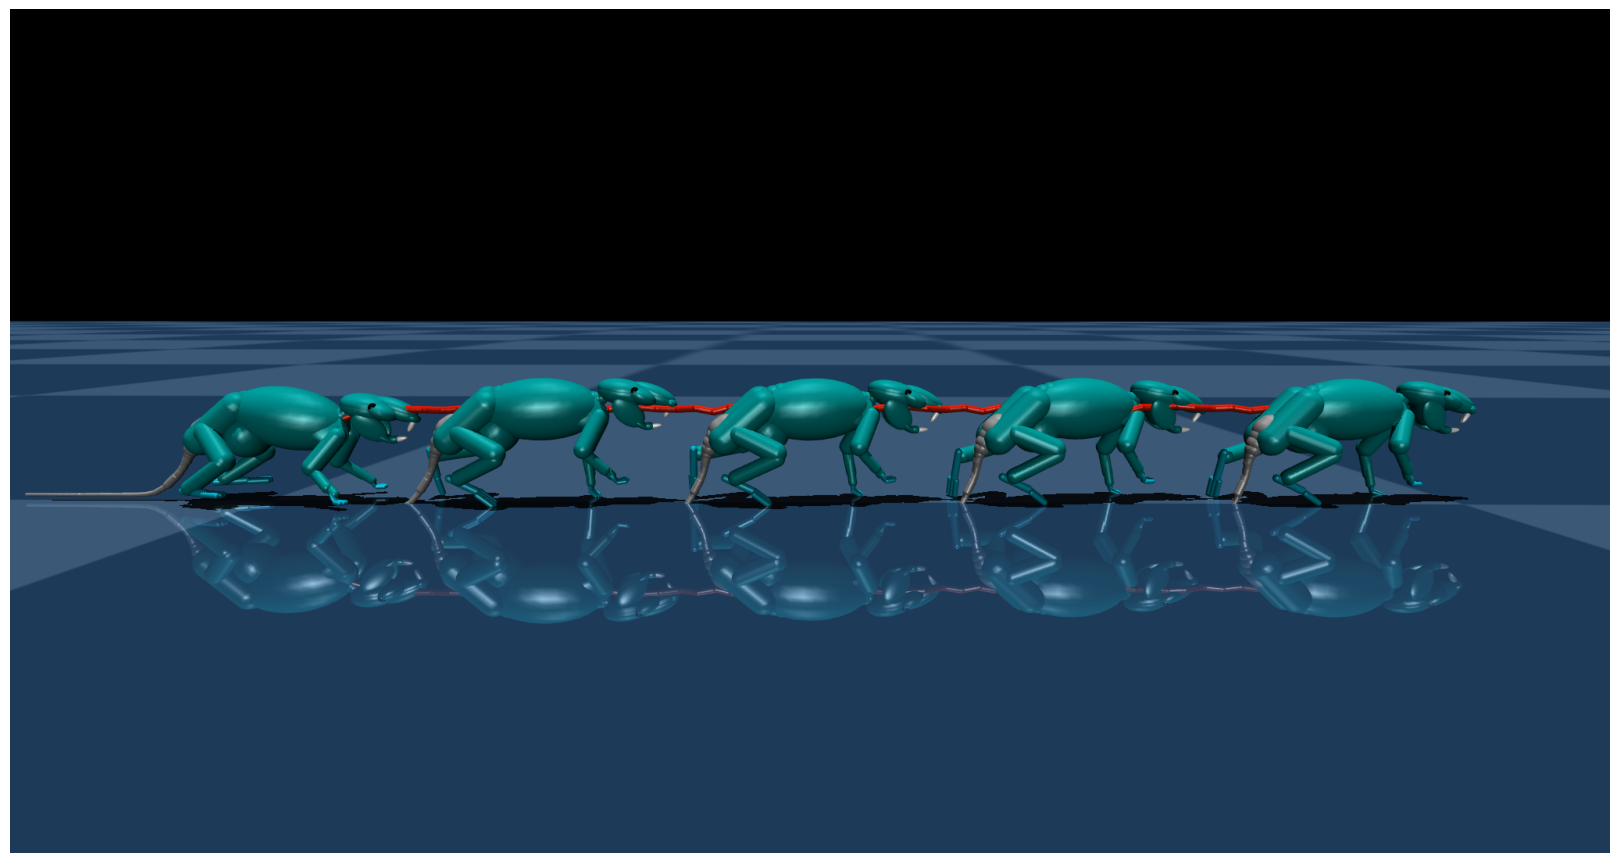

In [39]:
assert (
    captured_cam
), "Click 'Capture Camera' in the widget above before running this cell"

print(
    f"Azimuth: {captured_cam['azimuth']:.1f}  Elevation: {captured_cam['elevation']:.1f}  "
    f"Distance: {captured_cam['distance']:.2f}  Lookat: {captured_cam['lookat']}"
)

# Render at full resolution using the captured free camera
hires_cam = mujoco.MjvCamera()
hires_cam.type = mujoco.mjtCamera.mjCAMERA_FREE
hires_cam.azimuth = captured_cam["azimuth"]
hires_cam.elevation = captured_cam["elevation"]
hires_cam.distance = captured_cam["distance"]
hires_cam.lookat[:] = captured_cam["lookat"]

hires_renderer = mujoco.Renderer(
    trail_model, height=TRAIL_RENDER_HEIGHT, width=TRAIL_RENDER_WIDTH
)
hires_renderer.update_scene(trail_data, camera=hires_cam)
hires_frame = hires_renderer.render().copy()
hires_renderer.close()

# Display and save
run_id = Path(CHECKPOINT_PATH).name
save_name = f"trail_{NAME}_step{ckpt_step}_seed{SEED}_{run_id}"

fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(hires_frame)
ax.axis("off")
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

fig.savefig(OUTPUT_DIR / f"{save_name}.pdf", bbox_inches="tight", pad_inches=0)
fig.savefig(OUTPUT_DIR / f"{save_name}.svg", bbox_inches="tight", pad_inches=0)
fig.savefig(OUTPUT_DIR / f"{save_name}.png", bbox_inches="tight", pad_inches=0)
print(f"Saved to {OUTPUT_DIR / save_name}.[pdf|svg|png]")
plt.show()